# Lifespan Predictor — Interpretable Cox Model on NASA Turbofan Data

Predict **time to event** with a model you can read. A linear Cox model
gives each sensor one coefficient that says how it moves the risk of
failure, and it needs far fewer failures to fit than a neural network.
The subjects are aircraft engines from NASA's C-MAPSS dataset, and the
event is failure.

The notebook runs end to end with no edits. It tunes and trains the model
on SageMaker, scores it on the test engines, explains what drives risk
overall and for each engine, and deletes what it made.

It runs on either Lifespan Predictor product, including the **free
tier**: FD001 has 100 training engines, within the free
tier's cap of 100 units. See [Which product?](https://github.com/kooditurva/lifespan-predictor-sdk#which-product)
for the two products and their algorithm ARNs.

**What you need**: an active AWS Marketplace subscription to either
product, and a SageMaker execution role.

## 1. Install the SDK

The client SDK is installed from its GitHub release tag. It is not
published to PyPI.

In [ ]:
# Other releases: https://github.com/kooditurva/lifespan-predictor-sdk/releases
!pip install -q "lifespan-predictor @ git+https://github.com/kooditurva/lifespan-predictor-sdk@v1.1.0"

## 2. Point at the algorithm you subscribed to

The ARN below is the free tier's, in `eu-west-1`. If you subscribed to
the other product or work in another Region, use the ARN listed under
[Which product?](https://github.com/kooditurva/lifespan-predictor-sdk#which-product), or find it in the AWS Marketplace
console: **Manage subscriptions**, select the product, choose
**Continue to configuration**, and pick your Region.

The execution role is the IAM role SageMaker assumes to run your
training jobs. The SDK reads it from `SAGEMAKER_ROLE_ARN`. Outside
SageMaker Studio, set that variable before starting Jupyter; in Studio,
the cell below sets it from `get_execution_role()`.

In [2]:
import os

import matplotlib.pyplot as plt

from lifespan_predictor_sdk import (
    CategoricalRange,
    ContinuousRange,
    SurvivalModel,
    download_nasa_dataset,
    get_nasa_test_dataframe,
    get_nasa_train_dataframe,
)

ALGORITHM_ARN = 'arn:aws:sagemaker:eu-west-1:985815980388:algorithm/free-tier-lifespan-predictor-m-25f11987ba043299a755d4e16601168e'

if 'SAGEMAKER_ROLE_ARN' not in os.environ:
    from sagemaker import get_execution_role

    os.environ['SAGEMAKER_ROLE_ARN'] = get_execution_role()

### Check your setup

What the SDK will use. Set `SAGEMAKER_BUCKET` to keep the data and models
in a bucket of your own; otherwise SageMaker's default bucket for your
account and Region is used, and created if needed.

In [3]:
from importlib.metadata import version

import boto3

region = boto3.Session().region_name
arn_region = ALGORITHM_ARN.split(':')[3]

print('SDK version:        ', version('lifespan-predictor'))
print('Region:             ', region)
print('AWS_PROFILE:        ', os.environ.get('AWS_PROFILE', '(not set)'))
print('SAGEMAKER_ROLE_ARN: ', os.environ['SAGEMAKER_ROLE_ARN'])
print('SAGEMAKER_BUCKET:   ', os.environ.get(
    'SAGEMAKER_BUCKET', "(not set: SageMaker's default bucket)"))
print('Algorithm ARN:      ', ALGORITHM_ARN)

if region != arn_region:
    print(f'Warning: the session is in {region}, but the algorithm is in '
          f'{arn_region}. Use the ARN for your Region.')

SDK version:         1.1.0
Region:              eu-west-1
AWS_PROFILE:         (not set)
SAGEMAKER_ROLE_ARN:  arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker
SAGEMAKER_BUCKET:    kooditurva-lifespan-predictor-buyer-ci
Algorithm ARN:       arn:aws:sagemaker:eu-west-1:985815980388:algorithm/free-tier-lifespan-predictor-m-25f11987ba043299a755d4e16601168e


Every model in this notebook trains on that algorithm and instance type.

In [4]:
SAGEMAKER = {
    'algorithm_arn': ALGORITHM_ARN,
    'instance_type': 'ml.m5.large',
}

## 3. Load the NASA turbofan data

FD001 is one of the four C-MAPSS sub-datasets: simulated engines, each
observed once per flight cycle until it fails. The SDK downloads it and
returns it in the shape the algorithm expects:

| column | meaning |
|---|---|
| `unit` | the engine |
| `cycles` | the flight cycle within its history: `1, 2, 3, …` |
| `duration`, `event` | how long it ran, and whether it failed |
| everything else | operating settings and sensor readings |

The test engines' histories stop before failure. `test_labels_df` holds
their true remaining life, one row per engine, to score against.

In [5]:
data_dir = 'data/nasa'
download_nasa_dataset(data_dir, datasets=[1])

train_df = get_nasa_train_dataframe(data_dir, datasets=[1])
test_df, test_labels_df = get_nasa_test_dataframe(data_dir, datasets=[1])

print(f"Training: {train_df['unit'].nunique()} engines, {len(train_df)} rows")
print(f"Test:     {test_df['unit'].nunique()} engines, {len(test_df)} rows")
train_df.head()

Training: 100 engines, 20631 rows
Test:     100 engines, 13096 rows


,unit,cycles,setting_1,setting_2,setting_3,f1,f2,f3,f4,f5,...,f15,f16,f17,f18,f19,f20,f21,group,duration,event
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8.4195,0.03,392,2388,100.0,39.06,23.4190,0,192,1
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8.4318,0.03,392,2388,100.0,39.00,23.4236,0,191,1
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8.4178,0.03,390,2388,100.0,38.95,23.3442,0,190,1
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8.3682,0.03,392,2388,100.0,38.88,23.3739,0,189,1
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8.4294,0.03,393,2388,100.0,38.90,23.4044,0,188,1


## 4. Tune and train

`fit()` submits a SageMaker training job against the subscribed
algorithm. Nothing about the model runs locally.

A linear Cox model has no epochs, layers or learning rate. It is fitted
once, exactly, by maximising the penalised partial likelihood. What there
is to tune is the **penalty**:

- `coxph_penalizer` is its strength. Larger values shrink the coefficients
  towards zero, which steadies a fit on few failures or on many correlated
  sensors.
- `coxph_l1_ratio` is the share of it that is L1 (lasso) rather than L2
  (ridge). L1 can push coefficients to exactly zero, which selects features.
  `0` is pure ridge.
- `rolling_means` is tuned too, because it decides what the linear model
  gets to see: with it, each sensor also enters as its average over the
  last 5, 10, 20 or 30 cycles.

Each of the `n_trials` configurations is scored by 5-fold cross-validation
on the training engines, and the model is refitted on the best, all inside
the one training job. `max_rul` caps the remaining life the labels carry,
and `calibration='isotonic'` calibrates the predicted probabilities on the
engines `val_split` holds out. Passing the test set and its labels makes
the job score the model on them before it finishes.

In [6]:
model = SurvivalModel({
    **SAGEMAKER,
    'model_type': 'coxph',
    'max_rul': 125,
    'calibration': 'isotonic',
    # Each fit takes seconds, so trials are cheap: raise n_trials freely.
    'n_trials': 12,
    'coxph_penalizer': ContinuousRange(1e-3, 10.0, log=True),
    'coxph_l1_ratio': ContinuousRange(0.0, 1.0),
    'rolling_means': CategoricalRange([[], [5, 10, 20, 30]]),
    # To fit once without tuning, give plain values and leave out n_trials,
    # e.g. 'coxph_penalizer': 0.1, 'coxph_l1_ratio': 0.0, 'rolling_means': [5, 10].
})

model.fit(train_df, val_split=0.2, test_df=test_df, test_labels_df=test_labels_df)

val_split=0.2: 80 train units, 20 val units (16608 train rows, 4023 val rows)


🚀 Starting SageMaker training...


📦 S3 bucket: kooditurva-lifespan-predictor-buyer-ci
🔑 IAM Role: arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker
🔖 Algorithm ARN: arn:aws:sagemaker:eu-west-1:985815980388:algorithm/free-tier-lifespan-predictor-m-25f11987ba043299a755d4e16601168e
📤 Uploading raw CSV data to S3...
  ✓ Saved train.csv (16608 rows)


  ✓ Saved val.csv (4023 rows)
  ✓ Saved test.csv (13096 rows)
  ✓ Saved test_labels.csv (100 rows)


✓ Raw CSV uploaded to: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/training-1793214363
⚙️  Configuring training job...
📋 Training config keys: ['model_type', 'max_rul', 'calibration', 'n_trials', 'coxph_penalizer', 'coxph_l1_ratio', 'rolling_means', 'sdk_version']
📋 Config size: 368 chars


...

Training seconds: 911
Billable seconds: 911


✓ Training completed!

Training Job Summary:
  Name: survival-model-2026-10-28-19-06-05-627
  Status: Completed
  Training Time: 911 seconds
  Billable Time: 911 seconds
  Instance Type: ml.m5.large
  Model artifacts: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output/survival-model-2026-10-28-19-06-05-627/output/model.tar.gz
  Debug output: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output
  Hyperparameters: 1 configured

  Final Metrics:
    test:c_index: 0.8708
    test:rmse: 14.1321


✓ Training job: survival-model-2026-10-28-19-06-05-627
✓ Model artifact: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output/survival-model-2026-10-28-19-06-05-627/output/model.tar.gz
📥 Downloading training metrics...


✓ Test C-index: 0.8708
✓ Test RMSE: 14.1321
✓ Calibration bias: 0.0397 (well-calibrated)
✓ IBS: 0.0614 (excellent)


✓ tuning_trials loaded: 12 trials
✓ Training complete!


### The tuning trials

Each trial's values, and its C-index on each cross-validation fold with
their mean. The trial with the highest mean is the one the model was
refitted with.

In [7]:
import pandas as pd
from IPython.display import display

trials = model.get_tuning_trials()
best = trials.get_best_trial()

for trial in trials:
    values = ', '.join(
        f'{name}={value:.3g}' if isinstance(value, float) else f'{name}={value}'
        for name, value in trial.params.items())
    print(f"Trial {trial.number}{' (best)' if trial is best else ''}: {values}")
    scores = trial.fold_scores()
    if not scores:
        print(f'  {trial.state}, no fold scores')
        continue
    folds = [f'fold {i}' for i in range(1, len(scores) + 1)]
    table = pd.DataFrame([[*scores, trial.value]], columns=[*folds, 'mean'],
                         index=['C-index'])
    display(table.round(3))

Trial 0: coxph_penalizer=0.0315, coxph_l1_ratio=0.951, rolling_means=[]


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.869,0.85,0.843,0.882,0.862,0.861


Trial 1: coxph_penalizer=0.00421, coxph_l1_ratio=0.156, rolling_means=[5, 10, 20, 30]


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.915,0.902,0.905,0.903,0.906,0.906


Trial 2: coxph_penalizer=0.254, coxph_l1_ratio=0.708, rolling_means=[5, 10, 20, 30]


...

,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.868,0.85,0.843,0.883,0.862,0.861


Trial 10 (best): coxph_penalizer=0.00105, coxph_l1_ratio=0.489, rolling_means=[5, 10, 20, 30]


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.917,0.905,0.908,0.903,0.908,0.908


Trial 11: coxph_penalizer=0.00113, coxph_l1_ratio=0.331, rolling_means=[5, 10, 20, 30]


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.917,0.905,0.908,0.903,0.908,0.908


### Penalty against cross-validated C-index

Where the search found the good penalties. A flat curve means the penalty
hardly matters at this data size; a peak means it does.

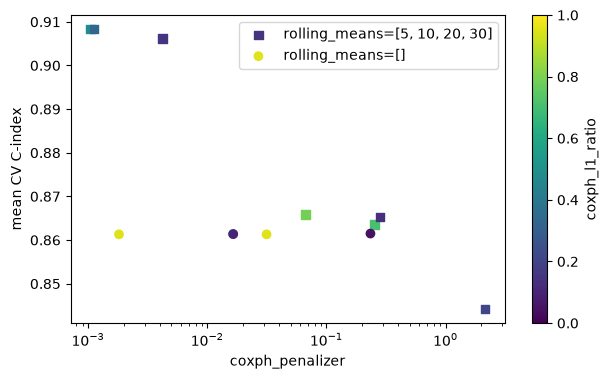

In [8]:
rows = [
    {'penalizer': t.params['coxph_penalizer'], 'l1_ratio': t.params['coxph_l1_ratio'],
     'rolling_means': str(t.params['rolling_means']), 'c_index': t.value}
    for t in trials if t.value is not None
]
search = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
for label, group in search.groupby('rolling_means'):
    points = ax.scatter(group['penalizer'], group['c_index'], c=group['l1_ratio'],
                        cmap='viridis', vmin=0, vmax=1, label=f'rolling_means={label}',
                        marker='o' if label == '[]' else 's')
ax.set_xscale('log')
ax.set_xlabel('coxph_penalizer')
ax.set_ylabel('mean CV C-index')
ax.legend()
fig.colorbar(points, ax=ax, label='coxph_l1_ratio')
plt.show()

## 5. What drives the risk

This is what a Cox model offers that a neural network does not: a
coefficient per feature that says how it moves the risk of failure. But
the tuned model above is the wrong one to read.

### Why not read the tuned model's coefficients

Tuning maximised the C-index, and a weak penalty tends to rank best. With
rolling means, each sensor enters five times (itself and its 5, 10, 20 and
30-cycle means), and the five are almost copies of each other. With a weak
penalty the model splits a sensor's effect among them arbitrarily, in large
positive and negative pieces that cancel. Predictions use only the total,
so they are sound. Each piece on its own claims to be the effect of moving
one rolling mean "with everything else held fixed", which never happens in
the data.

In [9]:
import numpy as np

analysis = model.get_global_analysis()
# The strongest sensor, with whichever of its rolling means the tuned model kept.
sensor = analysis.feature_effects.abs().idxmax()
family = [name for name in analysis.coefficients.index
          if name == sensor or name.startswith(f'{sensor}_rolling_mean_')]

print(f"{analysis.failed_units} failed engines, "
      f"{analysis.failed_units_per_feature:.1f} per feature\n")
print(analysis.coefficients.loc[family, ['coef', 'hazard_ratio', 'hr_lower_95',
                                         'hr_upper_95']].round(3))

80 failed engines, 0.7 per feature

                      coef  hazard_ratio  hr_lower_95  hr_upper_95
f8                   0.073         1.076        0.813        1.423
f8_rolling_mean_5    1.061         2.889        1.641        5.083
f8_rolling_mean_10   3.293        26.917        8.291       87.385
f8_rolling_mean_20   4.204        66.952        4.714      950.922
f8_rolling_mean_30 -11.426         0.000        0.000        0.000


`get_global_analysis()` returns the model's global analysis: what training
learnt about how the model acts on any engine. Besides the coefficient
table, it has `feature_effects`, one number per raw sensor, which adds a
sensor's pieces back up (see below).

That undoes the split within one sensor, not the split between sensors.
Some sensors are near-copies of each other too, such as core speed and
corrected core speed (`f9` and `f14`), and a weak penalty splits a shared
effect between them just as freely. So even a sensor's total can come out
large, or with the wrong sign, offset by its twin.

The explanation therefore comes from two refits with a firmer ridge penalty
(`0.1`), which spreads a shared effect evenly instead of letting it cancel.
Both rank worse than the tuned model: they are fitted to be read, not to
predict. **Each is a training job of its own.**

- **Raw sensors**: one coefficient per sensor, read directly.
- **With rolling means**: the same features as the tuned model, summed per
  sensor.

Where the two agree on a sensor's direction, the finding does not depend on
how the features were built. Where they disagree, it does, and it should not
be read as settled.

In [10]:
import contextlib
import io
import warnings


def explain(**config):
    explainer = SurvivalModel({
        **SAGEMAKER,
        'model_type': 'coxph',
        'max_rul': 125,
        'coxph_penalizer': 0.1,
        'coxph_l1_ratio': 0.0,
        **config,
    })
    # Quiet: these jobs' logs would repeat section 4's.
    with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
        warnings.simplefilter('ignore')
        explainer.fit(train_df)
    return explainer.get_global_analysis()


raw_analysis = explain(rolling_means=[])
rolled_analysis = explain(rolling_means=[5, 10, 20, 30])

### Raw sensors

For each sensor:

- `coef` is its effect on the log-hazard. Positive means more risk.
- `hazard_ratio` is `exp(coef)`. Features are min-max scaled to [0, 1] on
  the training data, so it compares an engine at that sensor's training
  **minimum** with one at its **maximum**, all else equal. `2.0` means twice
  the instantaneous risk of failure.
- `hr_lower_95` and `hr_upper_95` bound it. Their standard errors are
  clustered by engine, so the many rows of one engine count as one
  observation. With a penalty, they are the intervals of the penalised
  estimate, a guide rather than exact inference.
- `p` tests whether the coefficient differs from zero.

The seven sensors that never change in FD001 are left out of the fit; they
show as coefficient 0 with no interval.

In [11]:
raw = raw_analysis.coefficients.dropna(subset=['p'])
raw.reindex(raw['coef'].abs().sort_values(ascending=False).index).round(3)

,coef,hazard_ratio,hr_lower_95,hr_upper_95,p
f9,3.418,30.519,18.456,50.467,0.000
f14,3.278,26.512,16.794,41.854,0.000
f11,1.355,3.876,3.251,4.622,0.000
f4,1.213,3.364,2.814,4.021,0.000
f12,-1.158,0.314,0.247,0.399,0.000
f7,-1.127,0.324,0.267,0.393,0.000
f15,0.940,2.560,2.200,2.980,0.000
f20,-0.799,0.450,0.384,0.526,0.000
f13,0.777,2.174,1.439,3.284,0.000
f21,-0.770,0.463,0.404,0.531,0.000


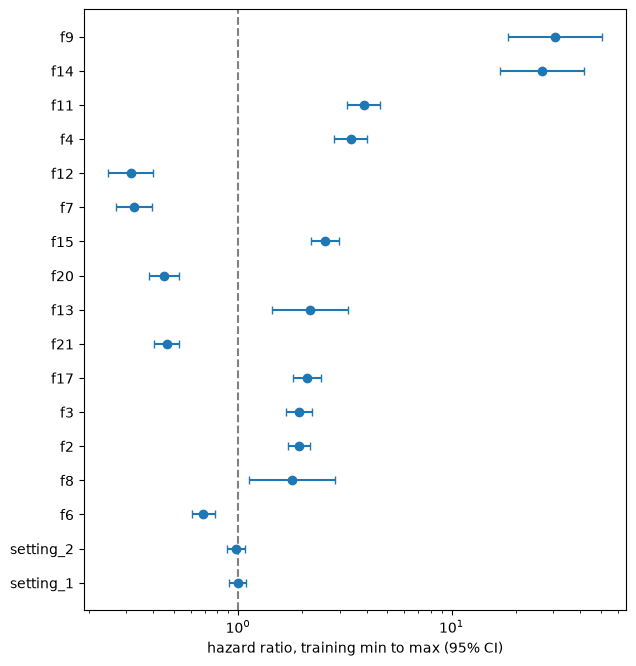

In [12]:
fig, ax = raw_analysis.plot_hazard_ratios()

### With rolling means, per sensor

`feature_effects` gives each sensor's effect on the log-hazard when it
shifts by its training range and stays there, so its rolling means shift
with it. Each rolling mean was scaled by its own training range, and longer
windows have narrower ranges, so the algorithm converts each coefficient
back to raw units before summing. The result is on the same scale as `coef`
in the raw-sensor table.

The last column is the tuned model's own `feature_effects`. Where it
disagrees with both refits, even in sign, read it as the split between
near-copy sensors described above, not as a finding.

In [13]:
effects = pd.DataFrame({
    'raw sensors': raw['coef'],
    'with rolling means': rolled_analysis.feature_effects[raw.index],
    'tuned model': analysis.feature_effects[raw.index],
})
effects['agree'] = np.sign(effects['raw sensors']) == np.sign(effects['with rolling means'])
effects.reindex(effects['raw sensors'].abs().sort_values(ascending=False).index).round(2)

,raw sensors,with rolling means,tuned model,agree
f9,3.42,3.02,-3.36,True
f14,3.28,2.93,2.99,True
f11,1.35,2.25,4.21,True
f4,1.21,2.64,4.81,True
f12,-1.16,-1.69,-2.03,True
f7,-1.13,-1.88,-1.77,True
f15,0.94,1.05,1.37,True
f20,-0.80,-0.54,-0.12,True
f13,0.78,-0.81,-4.61,False
f21,-0.77,-0.50,-0.14,True


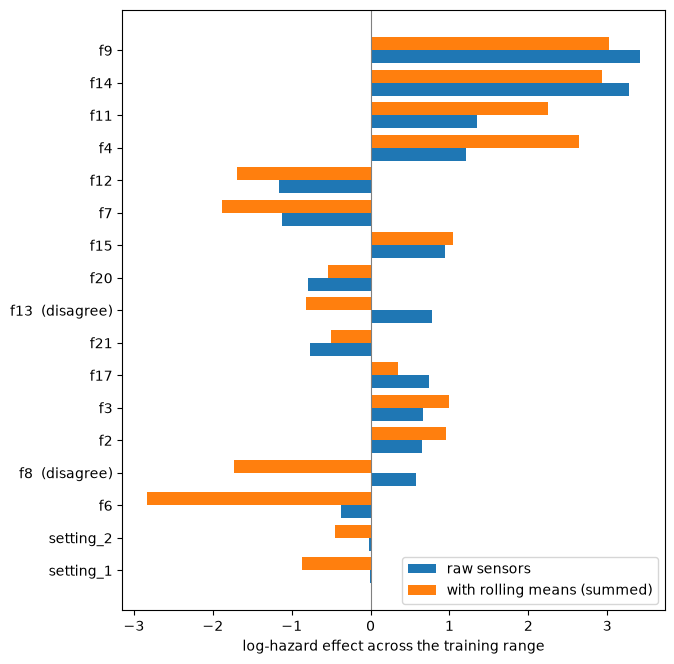

In [14]:
order = effects['raw sensors'].abs().sort_values().index
fig, ax = plt.subplots(figsize=(7, 0.4 * len(order) + 1))
y = np.arange(len(order))
ax.barh(y - 0.2, effects.loc[order, 'raw sensors'], height=0.4, label='raw sensors')
ax.barh(y + 0.2, effects.loc[order, 'with rolling means'], height=0.4,
        label='with rolling means (summed)')
ax.axvline(0, color='grey', linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels([f'{s}{"" if effects.loc[s, "agree"] else "  (disagree)"}'
                    for s in order])
ax.set_xlabel('log-hazard effect across the training range')
ax.legend()
plt.show()

### Proportional hazards

The Cox model assumes each sensor's effect on risk is constant over an
engine's life. This test, from the raw-sensor fit, asks per sensor whether
the data contradicts that. A small `p` means the effect drifts with time.

It treats rows as independent, so with many rows per engine its p-values
come out too small. Read it as a ranking of which sensors break the
assumption most, not as a verdict.

In [15]:
raw_analysis.ph_test.dropna().sort_values('p').round(4)

,test_statistic,p
f11,125.8460,0.0000
f2,88.3648,0.0000
f7,82.1329,0.0000
f15,77.2497,0.0000
f21,61.7705,0.0000
f12,61.3456,0.0000
f6,58.4639,0.0000
f4,58.0681,0.0000
f20,51.0853,0.0000
f17,34.4558,0.0000


## 6. Results

The training job's scores on the test engines: C-index (ranking, `0.5` is
a coin flip), RMSE (error in predicted remaining life, in cycles) and the
calibration curve.

=== Evaluation Metrics ===
  Scored on 100 units. 11 have a true remaining life beyond max_rul=125, the
  horizon the model predicts: RMSE counts them as 125, and the C-indices and
  IBS treat them as censored at 125. Calibration bias uses the 89 that
  failed within max_rul=125.
  C-index (IPCW):       0.8708  (higher is better, 0.5 = random; corrected for censoring)
  C-index (Harrell):    0.8708  (uncorrected; the tuning metric)
  C-index (Antolini):   0.8708  (higher is better, time-dependent)
  RMSE:                 14.1321  (lower is better)
  IBS:                  0.0614  (lower is better, <0.1 = excellent)  (excellent)
  Calibration bias:     0.0397  (closer to 0 is better)  (well-calibrated)
Prediction arrays not available (e.g. SageMaker backend).


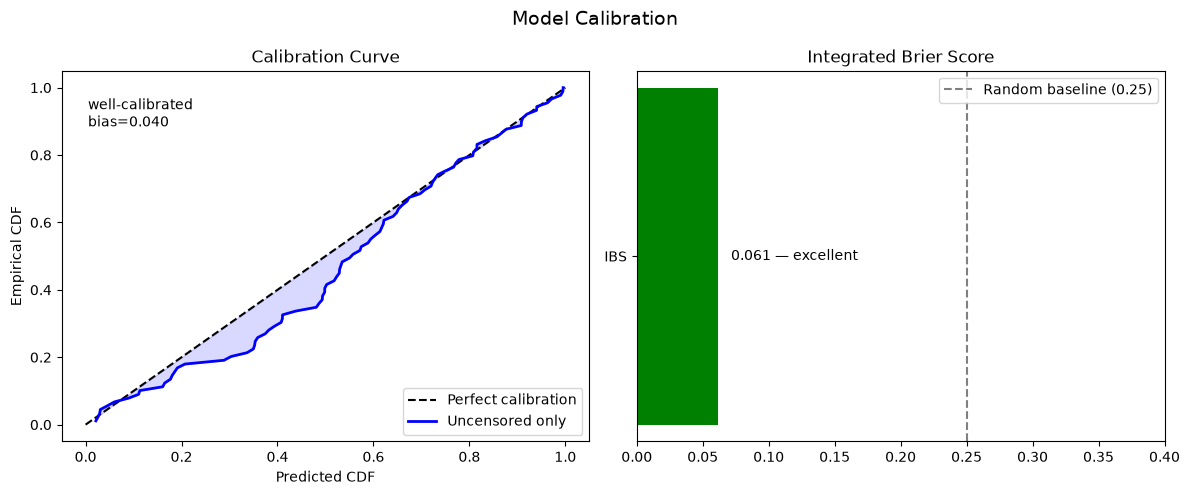

In [16]:
model.get_evaluation_result().report()

## 7. Predict

`deploy()` turns the trained estimator into a SageMaker **Model**. Then
`predict()` runs a batch transform job and returns, for each engine, the
probability of still running after each number of further cycles,
predicted from the end of its history.

In [17]:
model_name = model.deploy()
print('Created SageMaker model:', model_name)

🚀 Creating SageMaker Model for batch transform...
🔑 IAM Role: arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker


📦 Model name: coxph-2026-10-28-19-29-13-545
✅ Model created successfully!
   Ready for batch transform inference

Next steps:
  mean_times = model.predict_mean(test_df)

Created SageMaker model: coxph-2026-10-28-19-29-13-545


🔮 Running batch transform for mean survival predictions...
   Input: 13096 samples
📤 Uploading input data to S3...


✓ Input uploaded: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/batch-input-1793215806/input.csv


🏃 Starting batch transform job...
   Instance: ml.m5.large (count: 1)


.

.

...

.

[2026-10-28 19:34:45 +0000] [1] [INFO] Starting gunicorn 26.2.0
[2026-10-28 19:34:45 +0000] [1] [INFO] Listening at: http://0.0.0.0:8080 (1)
[2026-10-28 19:34:45 +0000] [1] [INFO] Using worker: sync
[2026-10-28 19:34:45 +0000] [6] [INFO] Booting worker with pid: 6
[2026-10-28 19:34:46 +0000] [1] [INFO] Control socket listening at /root/.gunicorn/gunicorn.ctl
Starting model loading in background thread...
Loading model from /opt/ml/model...
Loading model from /opt/ml/model
✓ Model loaded successfully
  Model type: coxph
  Features: 120
✓ Model loaded successfully


2026-10-28T19:34:55.622:[sagemaker logs]: MaxConcurrentTransforms=1, MaxPayloadInMB=6, BatchStrategy=MULTI_RECORD
✅ Batch transform complete!
📥 Downloading results from S3...


   Found 1 output file(s)


✓ Results downloaded: 100 predictions
100 survival curves, one per test engine


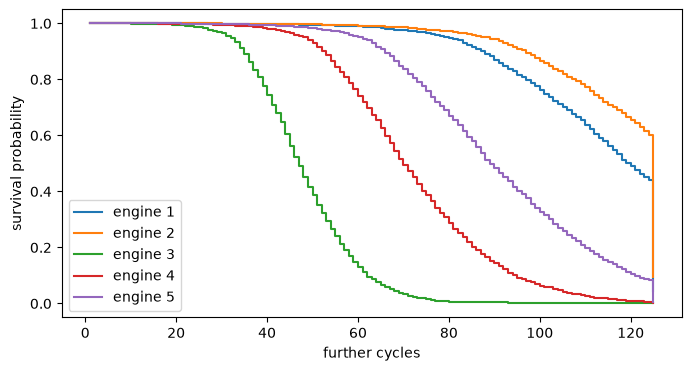

In [18]:
curves = model.predict(test_df)
units = sorted(test_df['unit'].unique())
print(f'{curves.shape[1]} survival curves, one per test engine')

ax = curves.iloc[:, :5].plot(drawstyle='steps-post', figsize=(8, 4))
ax.set_xlabel('further cycles')
ax.set_ylabel('survival probability')
ax.legend([f'engine {u}' for u in units[:5]])
plt.show()

## 8. What drives each engine's risk

Every `predict()` also explains itself, from the same batch transform.
`get_local_analysis()` returns, for each engine just predicted, how much
each sensor raises (positive) or lowers (negative) its log-hazard at the
last cycle of its history, compared with the average training row. The
parts add up exactly to the engine's log hazard ratio, so nothing is
approximated, and each sensor's rolling means count towards that sensor.

In [19]:
local = model.get_local_analysis()
# Sensors that never change contribute nothing to any engine.
contributions = local.contributions.loc[:, local.contributions.abs().max() > 0]
risk_order = local.log_hazard_ratio.sort_values(ascending=False).index

print(f'{len(contributions)} engines, {contributions.shape[1]} sensors')
contributions.assign(log_hazard_ratio=local.log_hazard_ratio).loc[risk_order].head().round(2)

100 engines, 17 sensors


,setting_1,setting_2,f2,f3,f4,f6,f7,f8,f9,f11,f12,f13,f14,f15,f17,f20,f21,log_hazard_ratio
unit,,,,,,,,,,,,,,,,,,
34,0.03,-0.05,0.76,0.24,1.45,-0.07,1.05,-0.41,-0.05,2.35,1.46,-0.03,-0.27,0.72,0.34,0.42,0.35,8.29
76,0.07,-0.00,0.55,0.21,1.49,-0.07,0.89,0.10,-0.30,1.58,0.97,-0.17,0.49,0.70,0.37,0.42,0.42,7.71
82,-0.00,0.07,0.67,0.04,1.18,-0.07,1.03,-0.45,-0.05,1.89,1.12,0.15,-0.22,0.93,0.32,0.42,0.21,7.23
68,-0.06,0.02,0.78,0.30,1.29,-0.07,0.90,-0.18,-0.09,1.45,1.08,-0.09,0.17,0.61,0.37,0.25,0.24,6.98
42,-0.00,-0.01,0.59,0.18,1.13,-0.07,1.24,-0.22,0.22,1.39,1.02,-0.19,-0.44,0.60,0.24,0.64,0.46,6.78


### Do engines share explanations?

Each row is one engine, riskiest at the top; each column is a sensor, the
most influential on the left. Red raises risk, blue lowers it.

One thing to know before reading it. In a linear model, every engine shares
the same coefficients, so a sensor always pushes risk the same way whenever
it sits above its training average. Engines can differ only in *which*
sensors have drifted, and by how much. Rows that look alike mean the engines
wore along the same sensors; they cannot mean the model reasoned differently
about them.

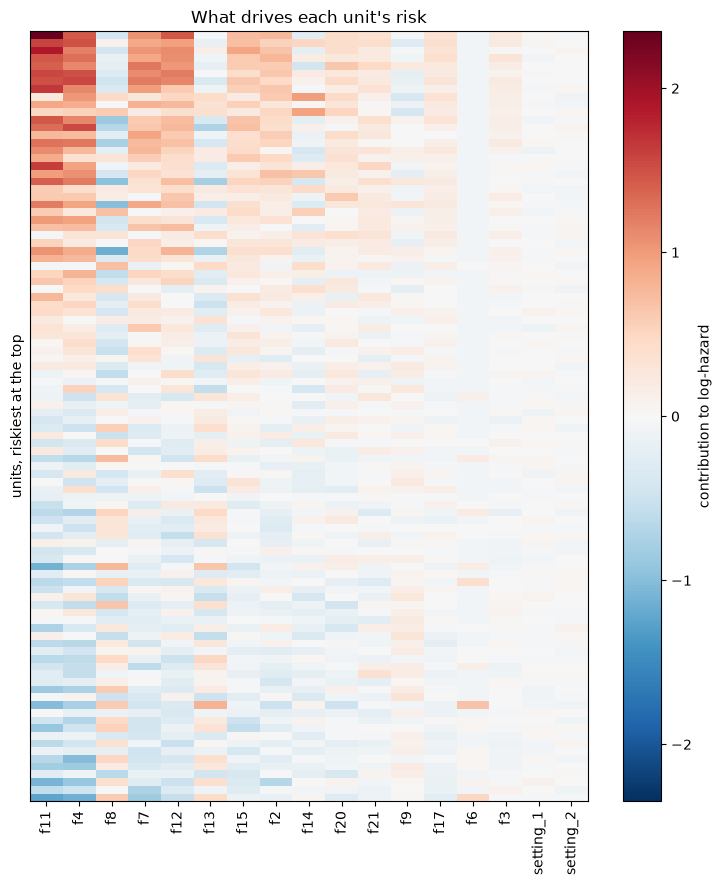

In [20]:
fig, ax = local.plot_contributions()

The sensor that contributes most to each engine, by size, and how often each
one is the top driver. One sensor on top for nearly every engine means one
shared pattern. Several sensors sharing the top spot mean engines wear in
different ways only if those sensors measure different things. The next
section checks that.

In [21]:
top_driver = local.top_drivers()
top_driver.value_counts().rename('engines where it is the top driver').to_frame()

,engines where it is the top driver
top_driver,
f11,39
f4,19
f8,14
f13,10
f7,9
f12,4
f14,2
f15,2
f2,1


### Which sensors move together

FD001 engines wear in one way, and most sensors see it, so many of them rise
and fall together. Two such sensors carry the same information, and which of
them comes out on top for an engine can depend on noise. The table above
would then show two names for one pattern.

The matrix below correlates the sensors' contributions across the test
engines. A contribution is the sensor's coefficient times its distance from
the training average, so two contributions correlate as the sensors
themselves do, with the sign flipped when the coefficients have opposite
signs. Red means the two sensors push risk the same way, blue opposite ways.
The sensors are ordered by hierarchical clustering, so the groups that move
together show up as blocks along the diagonal.

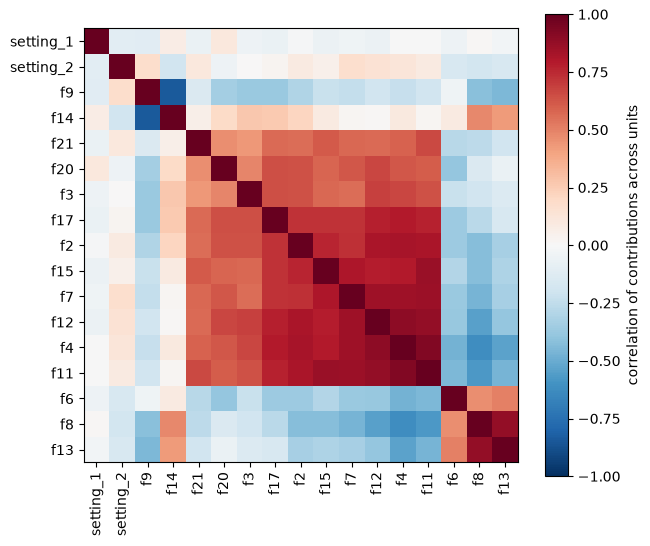

In [22]:
fig, ax = local.plot_feature_correlation()

Sensors whose contributions correlate by about `|r| > 0.7` form one group
below. The contributions add up exactly, so a group's contribution is the
sum of its sensors', and the top-driver count can be repeated per group.
Where the table above split the top spot between sensors of one group, this
one counts them together.

In [23]:
groups = local.feature_groups(min_correlation=0.7)

group_top_driver = local.top_drivers(groups)
group_top_driver.value_counts().rename('engines where it is the top driver').to_frame()

,engines where it is the top driver
top_driver,
f2 + f4 + f7 + f11 + f12 + f15 + f17,83
f8 + f13,16
f21,1


### What the groups mean

The columns are C-MAPSS's sensors, `fN` for sensor N, so the groups can be
read physically. The sensor names are from Saxena et al. (2008), *Damage
propagation modeling for aircraft engine run-to-failure simulation*.

| Column | Sensor |
|---|---|
| f2, f3, f4 | total temperature at the low-pressure compressor, HPC and low-pressure turbine outlets |
| f7 | total pressure at the HPC outlet |
| f8, f13 | fan speed, physical and corrected |
| f9, f14 | core speed, physical and corrected |
| f11 | static pressure at the HPC outlet |
| f12 | ratio of fuel flow to that static pressure |
| f15 | bypass ratio |
| f17 | bleed enthalpy |
| f20, f21 | high- and low-pressure turbine coolant bleed |

FD001 simulates one fault: a degrading high-pressure compressor (HPC). A
compressor that loses efficiency runs hotter, its pressures shift, and fuel
flow, bypass ratio and bleed follow. Those sensors are not separate signals
but readings of one fault, which is why they correlate and fall into one
group. Exactly which sensors join it depends on the fit and on the `|r|`
cut. When that group is the top driver for most engines, the model has found
one wear mechanism, and the physically right one. The spread over many
sensors in the first table then came mostly from the correlation.

A group that leads only a few engines, such as fan speed, can mean two
things. Those engines may wear differently. Or they have barely worn, so
every contribution is near zero and the top driver is only the largest of
several small numbers. A single sensor leading one engine is most likely
noise. The cell below tells the first two apart.

In [24]:
dominant = group_top_driver.value_counts().index[0]
others = group_top_driver[group_top_driver != dominant]
risk_rank = pd.Series(range(len(risk_order)), index=risk_order)

pd.DataFrame({
    'led by': others,
    'risk rank (0 = riskiest)': risk_rank[others.index],
    'log hazard ratio': local.log_hazard_ratio[others.index],
}).sort_values('risk rank (0 = riskiest)').round(2)

,led by,risk rank (0 = riskiest),log hazard ratio
unit,,,
32,f8 + f13,30,1.89
17,f8 + f13,33,1.22
13,f8 + f13,42,0.08
4,f8 + f13,43,0.00
8,f8 + f13,44,-0.10
80,f21,45,-0.14
11,f8 + f13,46,-0.37
70,f8 + f13,52,-0.49
5,f8 + f13,57,-0.80


These are the engines the dominant group does not lead. If they sit near the
bottom of the risk order, with log hazard ratios near or below zero, their
top driver is a near-tie among healthy engines, and the honest summary is one
wear pattern for every engine that is wearing. If some of them rank high, the
group that leads them is a second pattern worth a closer look.

### Engines explained alike

Cosine similarity compares two engines' explanations by direction alone:
`1` means the same sensors in the same proportions, `0` unrelated sensors,
`-1` the mirror image. In the matrix below, engines are again in risk order,
so blocks along the diagonal are groups of engines explained alike.

A healthy engine's explanation tends to be the mirror image of a worn one's:
the same sensors, below average instead of above. So the useful comparison
is within a risk group, summarised under the plot.

Correlated sensors raise these similarities too. Two engines worn along the
same group of sensors look alike in every sensor of that group, so the
similarities say how much of the wear is shared, not how many sensors agree
independently.

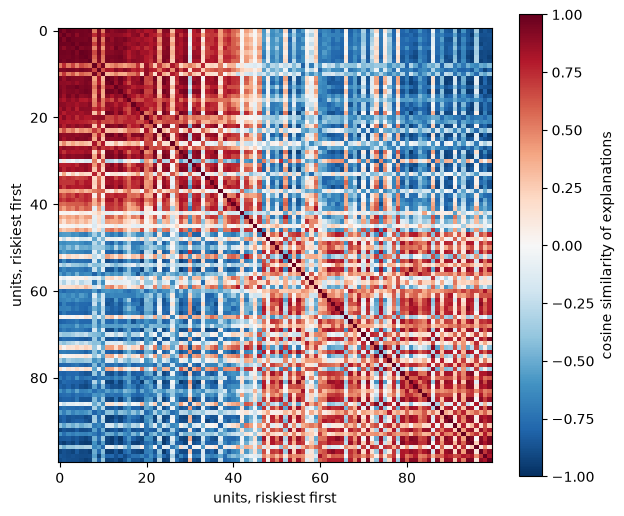

,mean similarity between its engines
riskiest quarter,0.78
middle half,0.00
safest quarter,0.46


In [25]:
fig, ax = local.plot_similarity()
similarity = local.similarity().loc[risk_order, risk_order].to_numpy()


def mean_similarity(rows):
    block = similarity[np.ix_(rows, rows)]
    return block[~np.eye(len(rows), dtype=bool)].mean()


n = len(similarity)
risk_groups = {
    'riskiest quarter': range(0, n // 4),
    'middle half': range(n // 4, 3 * n // 4),
    'safest quarter': range(3 * n // 4, n),
}
pd.Series({name: mean_similarity(list(rows)) for name, rows in risk_groups.items()},
          name='mean similarity between its engines').round(2).to_frame()

## 9. Clean up

Delete the SageMaker model this notebook created, so trying the product
doesn't leave anything behind. Training and transform jobs are billed for
the time they ran and stop on their own; there is nothing to delete for
those.

In [26]:
model.delete()
print('Deleted', model_name)

Deleted coxph-2026-10-28-19-29-13-545


## Where to go next

- **Few failures**: subsample the training engines, e.g.
  `train_df[train_df['unit'] <= 20]`. Below 10 failed engines, the model
  warns that its intervals are unreliable.
- **Feature selection**: fix `coxph_l1_ratio` near `1` and raise
  `coxph_penalizer` to see which sensors survive as the lasso pushes the
  rest to zero.
- **Your own data**: rows per unit over time, with `unit`, `cycles`,
  `duration`, `event` and your features. On the free tier, train on at
  most 100 units.

Full documentation is in the SDK repository:
https://github.com/kooditurva/lifespan-predictor-sdk